# Telco Customer Churn — Data Verification, Split and EDA

Group: 2026-DS-77

Lead contributor: IT24102420

Purpose:
Verify the supplied dataset, create a reproducible development/test
split, and investigate development data to inform preprocessing
and modelling.

Target: Churn

Positive class: Yes

Protocol:
- Preserve the original CSV.
- Use a fixed stratified 80% development / 20% test split.
- Conduct detailed exploratory analysis on development data only.
- Reserve test data for final evaluation after model and threshold selection.

Prior exposure:
Whole-file descriptive summaries were examined before adopting
this protocol. Subsequent exploratory analysis and model selection
will use development data.


In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
#Locate your CSV
from pathlib import Path
import hashlib
import json
import platform
from datetime import datetime, timezone

import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

RAW_FILE = Path(
    "/content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

assert RAW_FILE.is_file(), "CSV not found. Check the copied path."
assert RAW_FILE.parent.name == "raw", "Select the CSV inside data/raw."
assert RAW_FILE.parent.parent.name == "data", "Check the folder structure."

PROJECT_DIR = RAW_FILE.parent.parent.parent
SPLIT_DIR = PROJECT_DIR / "data" / "splits"

raw_hash = hashlib.sha256(RAW_FILE.read_bytes()).hexdigest()

print("Dataset:", RAW_FILE.name)
print("Project folder:", PROJECT_DIR)
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Dataset SHA-256:", raw_hash)

#The SHA-256 is a fingerprint of the file. It helps us check later that everyone used the same original dataset.
# Define output folders before any plotting or export cells run.
TABLE_DIR = PROJECT_DIR / "outputs" / "tables"
FIGURE_DIR = PROJECT_DIR / "outputs" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


Dataset: WA_Fn-UseC_-Telco-Customer-Churn.csv
Project folder: /content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn
Python: 3.13.16
pandas: 2.2.3
scikit-learn: 1.6.1
Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [3]:
#Load and verify the records
df = pd.read_csv(RAW_FILE, dtype={"customerID": "string"})

required_columns = {"customerID", "Churn", "TotalCharges"}
assert required_columns.issubset(df.columns), "Required columns are missing."

checks = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Missing customer IDs": df["customerID"].isna().sum(),
    "Duplicate customer IDs": df["customerID"].duplicated().sum(),
    "Exact duplicate rows": df.duplicated().sum(),
    "Missing target values": df["Churn"].isna().sum(),
})

display(checks.to_frame("Result"))
display(df.dtypes.astype(str).to_frame("Loaded data type"))

assert df["customerID"].notna().all(), "Investigate missing IDs."
assert df["customerID"].str.strip().ne("").all(), "Investigate blank IDs."
assert df["customerID"].is_unique, "Investigate repeated customer IDs."
assert not df.duplicated().any(), "Investigate duplicate rows."
assert df["Churn"].notna().all(), "Investigate missing targets."
assert set(df["Churn"].unique()) == {"Yes", "No"}, "Check target labels."

print("Basic structural checks passed.")

#repeated customer IDs could place the same customer in both development and test data. Invalid target labels could also make the split or later modelling incorrect.
#If an assertion fails, stop and investigate the message rather than deleting records to make it pass.

,Result
Rows,7043
Columns,21
Missing customer IDs,0
Duplicate customer IDs,0
Exact duplicate rows,0
Missing target values,0


,Loaded data type
customerID,string
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Basic structural checks passed.


In [4]:
#Check TotalCharges without choosing its treatment yet
total_text = df["TotalCharges"].astype("string").str.strip()

blank_total = total_text.isna() | total_text.eq("").fillna(False)
parsed_total = pd.to_numeric(total_text, errors="coerce")

unexpected_invalid = parsed_total.isna() & ~blank_total

print("Blank/missing TotalCharges:", int(blank_total.sum()))
print("Unexpected non-numeric TotalCharges:", int(unexpected_invalid.sum()))

assert not unexpected_invalid.any(), (
    "Investigate unexpected non-numeric TotalCharges values."
)

#This checks whether the column can be interpreted as numeric. It does not fill missing values, delete rows or change the original CSV. Member 3 will justify the eventual missing-value treatment.

Blank/missing TotalCharges: 11
Unexpected non-numeric TotalCharges: 0


In [5]:
#Create and save the fixed split
#We will use random seed 42 as a reproducibility choice. It is not a special or “better” seed, and we should not try different seeds to obtain nicer results.
#Stratification keeps the proportions of churners and non-churners approximately similar in the two subsets. A fixed random_state makes the split reproducible for the same input and procedure. Scikit-learn documentation
#This cell creates the split the first time. On later runs, it reuses the saved membership and checks the original file fingerprint.

SEED = 42
TEST_SIZE = 0.20

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = SPLIT_DIR / "split_manifest.csv"
record_path = SPLIT_DIR / "split_record.json"
development_path = SPLIT_DIR / "development.csv"
test_path = SPLIT_DIR / "test.csv"

paths = [
    manifest_path, record_path,
    development_path, test_path
]

if any(path.exists() for path in paths):
    assert all(path.exists() for path in paths), (
        "Some split files exist but others are missing. "
        "Investigate before creating or replacing anything."
    )

    record = json.loads(record_path.read_text(encoding="utf-8"))

    assert record["source_sha256"] == raw_hash, (
        "The original dataset differs from the file used for the saved split."
    )
    assert record["random_seed"] == SEED
    assert record["test_size"] == TEST_SIZE

    manifest = pd.read_csv(
        manifest_path, dtype={"customerID": "string"}
    )

    print("Reusing the existing split.")

else:
    development_ids, test_ids = train_test_split(
        df["customerID"],
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=df["Churn"]
    )

    manifest = df[["customerID"]].copy()
    manifest["split"] = "development"
    manifest.loc[
        manifest["customerID"].isin(test_ids), "split"
    ] = "test"

    record = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "source_filename": RAW_FILE.name,
        "source_sha256": raw_hash,
        "random_seed": SEED,
        "test_size": TEST_SIZE,
        "stratified_by": "Churn",
        "positive_class": "Yes",
        "python_version": platform.python_version(),
        "pandas_version": pd.__version__,
        "sklearn_version": sklearn.__version__,
        "prior_exposure": (
            "Whole-file descriptive summaries were examined "
            "before adopting this protocol."
        )
    }

    manifest.to_csv(manifest_path, index=False)
    record_path.write_text(
        json.dumps(record, indent=2), encoding="utf-8"
    )

    df[df["customerID"].isin(development_ids)].to_csv(
        development_path, index=False
    )
    df[df["customerID"].isin(test_ids)].to_csv(
        test_path, index=False
    )

    print("Created and saved the fixed split.")

assert manifest["customerID"].is_unique
assert set(manifest["customerID"]) == set(df["customerID"])
assert set(manifest["split"]) == {"development", "test"}

development_ids = set(
    manifest.loc[manifest["split"] == "development", "customerID"]
)
test_ids = set(
    manifest.loc[manifest["split"] == "test", "customerID"]
)

assert development_ids.isdisjoint(test_ids)
assert len(development_ids) + len(test_ids) == len(df)

print("Development records:", len(development_ids))
print("Reserved test records:", len(test_ids))
print("Split files saved in:", SPLIT_DIR)

#For a dataset containing 7,043 records, this should produce:
#- 5,634 development records
#- 1,409 reserved test records
#The slight difference from exact percentages is because records must be whole numbers.
# Validate saved file CONTENTS, not just their existence or customer-ID sets.
# This is an integrity check only: do not display or analyse test records.
for split_label, split_file in [
    ("development", development_path), ("test", test_path)
]:
    saved_subset = pd.read_csv(
        split_file, dtype={"customerID": "string"}, float_precision="round_trip"
    )
    expected_ids = manifest.loc[manifest["split"].eq(split_label), "customerID"]
    expected_subset = df.loc[df["customerID"].isin(expected_ids)]
    assert saved_subset["customerID"].is_unique, "Repeated IDs in saved split."
    pd.testing.assert_frame_equal(
        saved_subset.sort_values("customerID").reset_index(drop=True),
        expected_subset.sort_values("customerID").reset_index(drop=True),
        check_dtype=False, check_exact=True
    )
print("Saved split contents match the source and manifest.")
del saved_subset, expected_subset, expected_ids


Reusing the existing split.
Development records: 5634
Reserved test records: 1409
Split files saved in: /content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn/data/splits
Saved split contents match the source and manifest.


In [6]:
#Switch to development data
dev = pd.read_csv(
    development_path,
    dtype={"customerID": "string"}
)

assert set(dev["customerID"]) == development_ids

# Remove the whole dataset from the notebook's active variables.
del df

print("Development data loaded:", dev.shape)
print("Use 'dev' for all subsequent exploratory analysis.")

Development data loaded: (5634, 21)
Use 'dev' for all subsequent exploratory analysis.


The manifest records which customer belongs to which subset. The record documents how the split was made.
Saving test.csv does not automatically restrict its Drive permissions. The leader should coordinate custody; members doing EDA, preprocessing and modelling should use development.csv


### Verification and split summary

The supplied CSV contains 7,043 customer records and 21 columns. Structural checks found no missing customer IDs, duplicate customer IDs, exact duplicate rows or missing churn labels.

The original file contains 11 blank TotalCharges values and no additional unexpected non-numeric values in that column. No records were deleted and no missing values were imputed during verification.

A fixed stratified split was created using random seed 42, producing 5,634 development records and 1,409 reserved test records. Split membership, the source-file fingerprint and environment versions were saved.

Subsequent exploratory analysis will use development data only. The reserved test set will be used after model settings and the classification threshold have been frozen.

In [7]:
#Create an EDA copy and interpret TotalCharges numerically
# Work on a separate development-data copy.
eda = dev.copy()

total_text = eda["TotalCharges"].astype("string").str.strip()
parsed_total = pd.to_numeric(total_text, errors="coerce")

blank_total = total_text.isna() | total_text.eq("").fillna(False)
unexpected_invalid = parsed_total.isna() & ~blank_total

assert not unexpected_invalid.any(), (
    "Unexpected non-numeric TotalCharges values require investigation."
)

eda["TotalCharges"] = parsed_total

print("Development records:", len(eda))
print(
    "Missing TotalCharges in development:",
    eda["TotalCharges"].isna().sum()
)

#we are interpreting recorded numbers as numbers and representing blanks as missing. We are not estimating replacement values or learning a transformation from the data.
#This changes only eda in memory. Your original CSV and saved split files stay as they are.

Development records: 5634
Missing TotalCharges in development: 8


In [8]:
#Examine the development target distribution
target_summary = (
    eda["Churn"]
    .value_counts()
    .reindex(["No", "Yes"], fill_value=0)
    .rename_axis("Churn")
    .to_frame("Customers")
)

target_summary["Percentage"] = (
    target_summary["Customers"] / len(eda) * 100
).round(2)

display(target_summary)

#This answers:How many development customers are labelled as churners and non-churners?

#The result will help explain why accuracy alone could be misleading. An unequal class distribution does not automatically mean that we must balance the data. That decision comes later.

,Customers,Percentage
Churn,,
No,4139,73.46
Yes,1495,26.54


In [9]:
#Build the first part of the data dictionary
#A data dictionary explains what each column represents and how we intend to treat it.
#First, generate an inventory of the development columns:

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

categorical_features = [
    column for column in eda.columns
    if column not in numeric_features + ["customerID", "Churn"]
]

def column_role(column):
    if column == "customerID":
        return "Identifier — exclude from model inputs"
    if column == "Churn":
        return "Target — Yes is the positive class"
    return "Candidate predictor"

def analytical_type(column):
    if column == "customerID":
        return "Identifier"
    if column == "Churn":
        return "Binary categorical target"
    if column in numeric_features:
        return "Numeric"
    return "Categorical"

data_inventory = pd.DataFrame({
    "Column": eda.columns,
    "Role": [column_role(c) for c in eda.columns],
    "Analytical type": [analytical_type(c) for c in eda.columns],
    "Loaded dtype": [str(dev[c].dtype) for c in eda.columns],
    "Distinct observed values": [
        eda[c].nunique(dropna=True) for c in eda.columns
    ],
    "Missing values": [
        eda[c].isna().sum() for c in eda.columns
    ],
})

display(data_inventory)

#Notice that SeniorCitizen is treated as categorical, even though Python loaded it as an integer. A numeric storage type does not necessarily mean that a column represents a numerical measurement.
#This table is a starting inventory, not the completed dictionary. We will add definitions, units and category meanings supported by the dataset documentation.

,Column,Role,Analytical type,Loaded dtype,Distinct observed values,Missing values
0,customerID,Identifier — exclude from model inputs,Identifier,string,5634,0
1,gender,Candidate predictor,Categorical,object,2,0
2,SeniorCitizen,Candidate predictor,Categorical,int64,2,0
3,Partner,Candidate predictor,Categorical,object,2,0
4,Dependents,Candidate predictor,Categorical,object,2,0
5,tenure,Candidate predictor,Numeric,int64,73,0
6,PhoneService,Candidate predictor,Categorical,object,2,0
7,MultipleLines,Candidate predictor,Categorical,object,3,0
8,InternetService,Candidate predictor,Categorical,object,3,0
9,OnlineSecurity,Candidate predictor,Categorical,object,3,0


In [10]:
#Investigate missing total charges
missing_total = eda["TotalCharges"].isna()

missing_total_summary = pd.Series({
    "Development records": len(eda),
    "Missing TotalCharges": int(missing_total.sum()),
    "Missing TotalCharges (%)": round(
        missing_total.mean() * 100, 3
    ),
})

display(missing_total_summary.to_frame("Value"))

if missing_total.any():
    print("Tenure among development records with missing TotalCharges:")

    display(
        eda.loc[missing_total, "tenure"]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("Tenure")
        .to_frame("Customers")
    )

#This tests whether missing total charges are associated with tenure zero in your development subset.
#Even if they are, that alone does not establish that replacing them with zero is correct. We will record the evidence for Member 3 to assess.

,Value
Development records,5634.000
Missing TotalCharges,8.000
Missing TotalCharges (%),0.142


Tenure among development records with missing TotalCharges:


,Customers
Tenure,
0,8


In [11]:
#Inspect numerical ranges and recorded categories
print("Numeric feature summary:")
display(eda[numeric_features].describe().T)

print("\nRecorded categorical values:")
for column in categorical_features:
    values = sorted(eda[column].dropna().unique().tolist())
    print(f"{column}: {values}")

#This helps us identify:
#- Unusual numerical ranges that need investigation.
#- Categories that require encoding.
#- Meaningful categories such as No internet service or No phone service, which should not automatically be treated as missing.

Numeric feature summary:


,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.485091,24.568744,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,5634.0,64.929961,30.138105,18.4,35.6625,70.5,90.0,118.75
TotalCharges,5626.0,2302.604266,2279.173176,18.85,407.275,1398.125,3838.6125,8684.8



Recorded categorical values:
gender: ['Female', 'Male']
SeniorCitizen: [0, 1]
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


### Initial development-data findings

**EDA-01 — Target distribution**

The development subset contains 5,634 customers: 1,495 labelled as churners (26.54%) and 4,139 as non-churners (73.46%). An always-non-churn prediction would achieve 73.46% accuracy on these records but identify no churners.

**Implication:** Accuracy alone is insufficient for evaluating churn identification. This supports our planned use of average precision for model selection and precision, recall and F1 in final assessment. Class weighting or resampling will not be applied automatically.

**EDA-02 — Missing total charges**

After interpreting TotalCharges numerically, eight development records have missing values, representing approximately 0.142% of the subset. All eight have tenure zero.

**Implication:** The missingness may be related to the beginning of the customer relationship. This observation does not establish that zero is the correct replacement. The preprocessing member will justify the treatment; any learned replacement values must be estimated within training folds.

**EDA-03 — Variable roles**

The dataset contains one customer identifier, one binary target and 19 candidate predictors. SeniorCitizen is a categorical indicator despite being stored as an integer. TotalCharges requires numeric parsing.

**Implication:** CustomerID will be retained for traceability and excluded from model inputs. Churn will be used only as the target. Preprocessing will follow the meaning of each variable rather than its storage type alone.

### Numeric ranges and categorical values

Development-data tenure ranges from 0 to 72 months, with a median of 29 months. MonthlyCharges ranges from 18.40 to 118.75. Observed TotalCharges ranges from 18.85 to 8,684.80; eight values are missing.

These summaries show no negative values in the three numerical variables. They do not independently establish the absence of data errors or justify removing extreme values. The mean TotalCharges exceeds its median, suggesting a right-skewed distribution that will be examined visually.

The numerical features have different scales, which will inform model-specific preprocessing decisions.

Categories such as “No internet service” and “No phone service” represent recorded service states and will be preserved during exploration. Their consistency with the underlying service indicators will be checked. SeniorCitizen will be treated as categorical despite its integer storage type.

In [12]:
#check service-category consistency
#Before interpreting these categories, check whether they agree with the underlying service fields.
internet_addons = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

consistency_rows = []

no_internet = eda["InternetService"].eq("No")

for column in internet_addons:
    marked_no_internet = eda[column].eq("No internet service")

    consistency_rows.append({
        "Check": f"{column} agrees with InternetService",
        "Inconsistent records": int(
            (no_internet != marked_no_internet).sum()
        )
    })

no_phone = eda["PhoneService"].eq("No")
marked_no_phone = eda["MultipleLines"].eq("No phone service")

consistency_rows.append({
    "Check": "MultipleLines agrees with PhoneService",
    "Inconsistent records": int(
        (no_phone != marked_no_phone).sum()
    )
})

service_consistency = pd.DataFrame(consistency_rows)
display(service_consistency)

#What this checks: for example, whether someone recorded as having no internet service is also consistently labelled No internet service in the internet add-on columns.


,Check,Inconsistent records
0,OnlineSecurity agrees with InternetService,0
1,OnlineBackup agrees with InternetService,0
2,DeviceProtection agrees with InternetService,0
3,TechSupport agrees with InternetService,0
4,StreamingTV agrees with InternetService,0
5,StreamingMovies agrees with InternetService,0
6,MultipleLines agrees with PhoneService,0


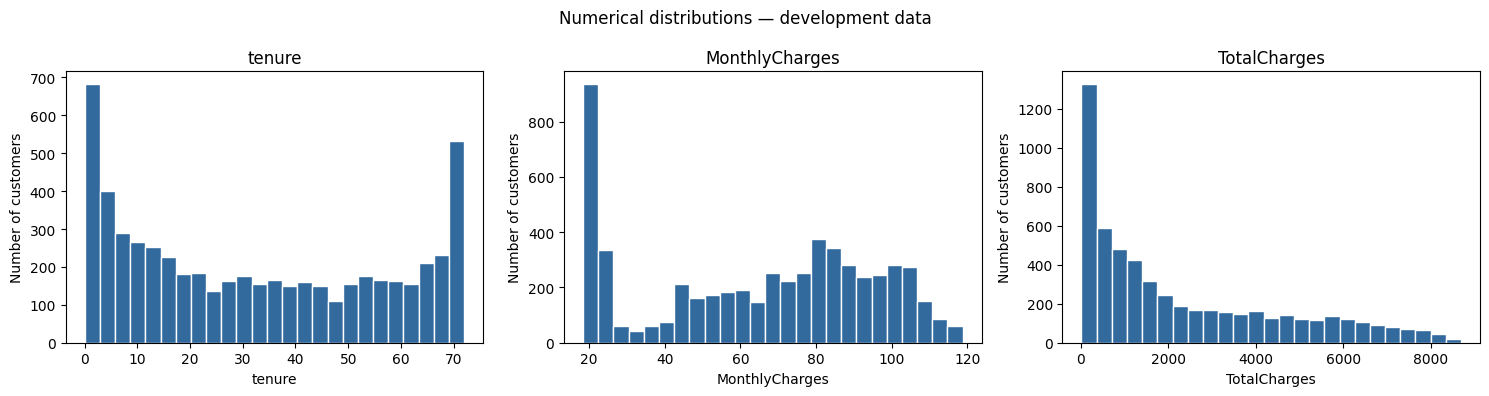

In [13]:
#visualise the numerical distributions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numeric_features):
    ax.hist(
        eda[column].dropna(),
        bins=25,
        color="#326A9E",
        edgecolor="white"
    )
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of customers")

fig.suptitle("Numerical distributions — development data")
plt.tight_layout()

# Save this figure before displaying it.
fig.savefig(
    FIGURE_DIR / "development_numeric_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#These charts answer “What does the development dataset look like?” They do not yet show relationships with churn.
#Look for concentrations, asymmetry and gaps. A long tail alone does not justify deleting observations.


In [14]:
#examine contract type and recorded churn
#We will begin with one relationship so you can understand the calculation before applying it to other features.
contract_summary = (
    eda.groupby("Contract", observed=True)
    .agg(
        Customers=("Churn", "size"),
        Churners=("Churn", lambda values: values.eq("Yes").sum())
    )
    .reindex(["Month-to-month", "One year", "Two year"])
)

contract_summary["Non-churners"] = (
    contract_summary["Customers"] - contract_summary["Churners"]
)

contract_summary["Churn percentage"] = (
    contract_summary["Churners"]
    / contract_summary["Customers"]
    * 100
).round(2)

display(contract_summary)

#The percentage is calculated within each contract category: Churn percentage = (Churners in that contract category / All customers in that contract category) times 100
#We report customer counts alongside percentages because categories may contain different numbers of customers.

,Customers,Churners,Non-churners,Churn percentage
Contract,,,,
Month-to-month,3102,1326,1776,42.75
One year,1173,130,1043,11.08
Two year,1359,39,1320,2.87


### Service consistency, numerical distributions and contract association

**EDA-04 — Service-category consistency**

No inconsistencies were found in the seven checks comparing internet add-on categories with InternetService and MultipleLines with PhoneService.

**Implication:** The checked service states are internally consistent in development data. Preserve these meaningful categories during exploration; these checks do not establish overall data correctness.

**EDA-05 — Numerical distributions**

Tenure shows concentrations at short durations and near the maximum recorded duration. MonthlyCharges has several concentrations. TotalCharges is visibly right-skewed, with many lower totals and fewer large totals.

**Implication:** These patterns inform further investigation and model-specific preprocessing. Distribution shape alone does not justify deleting extreme observations or applying transformations.

**EDA-06 — Contract type and recorded churn**

The recorded churn proportion is 42.75% among month-to-month customers (1,326/3,102), 11.08% among one-year customers (130/1,173), and 2.87% among two-year customers (39/1,359).

**Implication:** Contract type is associated with recorded churn and remains a relevant candidate predictor and profiling characteristic. These unadjusted comparisons do not establish causation or demonstrate that changing a customer's contract would prevent churn.

tenure               MonthlyCharges               TotalCharges          \
       count median   mean          count median   mean        count  median   
Churn                                                                          
No      4139   38.0  37.59           4139  64.40  61.34         4131  1691.9   
Yes     1495   10.0  18.36           1495  79.95  74.86         1495   740.3   

                
          mean  
Churn           
No     2569.69  
Yes    1564.59

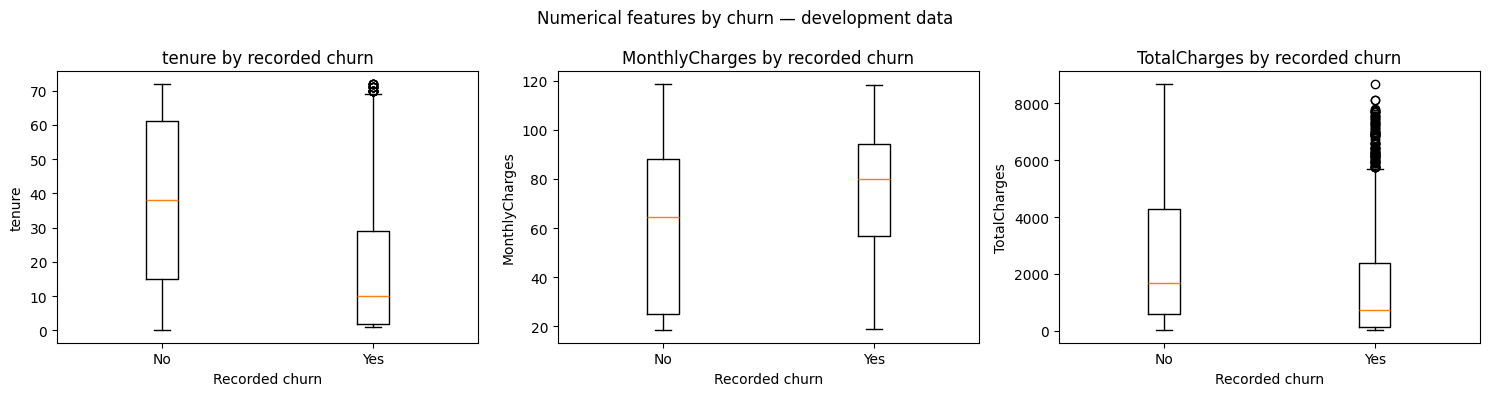

In [15]:
#compare numerical features between churners and non-churners
#We have examined numerical features overall. Now we ask:
#Do customers labelled as churners have different tenure and charge distributions from non-churners?

numeric_by_churn = (
    eda.groupby("Churn")[numeric_features]
    .agg(["count", "median", "mean"])
    .reindex(["No", "Yes"])
    .round(2)
)

display(numeric_by_churn)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numeric_features):
    groups = [
        eda.loc[eda["Churn"].eq(label), column].dropna()
        for label in ["No", "Yes"]
    ]

    ax.boxplot(groups, showfliers=True)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No", "Yes"])
    ax.set_xlabel("Recorded churn")
    ax.set_ylabel(column)
    ax.set_title(f"{column} by recorded churn")

fig.suptitle("Numerical features by churn — development data")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "development_numeric_by_churn.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#The count column excludes missing values for each numerical feature. Consequently, TotalCharges counts may be lower than the corresponding customer counts.

### EDA-07 — Numerical features and recorded churn

Recorded churners have a median tenure of 10 months, compared with 38 months among non-churners. Their median MonthlyCharges is higher (79.95 versus 64.40), while their median observed TotalCharges is lower (740.30 versus 1,691.90).

Shorter tenure is a possible explanation for lower accumulated charges despite higher monthly charges. Further examination of relationships between predictors is needed. The distributions overlap, so none of these features independently separates churners from non-churners.

All eight missing TotalCharges values occur among non-churners. Missing-value treatment must remain independent of the target label and any learned replacement values must be fitted within training folds.

**Implication:** Retain these numerical variables as candidate predictors at this stage. Investigate their relationships and model-specific preprocessing needs. These descriptive comparisons do not establish causation, predictive performance or a reason to remove boxplot outliers.

In [16]:
#examine the remaining categorical features
#We should examine all remaining categorical features consistently, rather than selecting only those that produce striking differences. The following cell creates one summary table and excludes contract type because you have already examined it.

categorical_results = []

for feature in categorical_features:
    if feature == "Contract":
        continue

    summary = (
        eda.groupby(feature, dropna=False, observed=True)
        .agg(
            Customers=("Churn", "size"),
            Churners=("Churn", lambda values: values.eq("Yes").sum())
        )
        .reset_index()
        .rename(columns={feature: "Category"})
    )

    summary.insert(0, "Feature", feature)

    summary["Non-churners"] = (
        summary["Customers"] - summary["Churners"]
    )

    summary["Churn percentage"] = (
        summary["Churners"] / summary["Customers"] * 100
    ).round(2)

    categorical_results.append(summary)

categorical_churn_summary = pd.concat(
    categorical_results,
    ignore_index=True
)

with pd.option_context("display.max_rows", None):
    display(categorical_churn_summary)

#Each row will show the churn percentage within that category, alongside the number of customers supporting it.

,Feature,Category,Customers,Churners,Non-churners,Churn percentage
0,gender,Female,2801,746,2055,26.63
1,gender,Male,2833,749,2084,26.44
2,SeniorCitizen,0,4714,1117,3597,23.70
3,SeniorCitizen,1,920,378,542,41.09
4,Partner,No,2905,952,1953,32.77
5,Partner,Yes,2729,543,2186,19.90
6,Dependents,No,3955,1240,2715,31.35
7,Dependents,Yes,1679,255,1424,15.19
8,PhoneService,No,559,135,424,24.15
9,PhoneService,Yes,5075,1360,3715,26.80


### EDA-08 — Categorical features and recorded churn

Development-data churn proportions differ substantially across payment methods, internet service types, online security, technical support and paperless billing categories. Electronic-check customers have a recorded churn proportion of 45.74%, compared with 14.92–19.28% for other payment methods. Fiber-optic customers have a proportion of 42.09%, compared with 18.69% for DSL customers and 7.25% for customers without internet service.

Demographic and household characteristics also show differences, although the gender comparison is nearly equal at 26.63% and 26.44%.

The repeated “No internet service” category across add-on variables represents the same 1,214 customers, including 88 churners. These repeated figures are not independent evidence of separate add-on effects.

**Implication:** Retain these results as exploratory associations and investigate relationships between predictors. Do not infer causation, model feature importance or effective retention interventions from these tables. Demographic differences require careful interpretation and do not independently justify differential treatment.

In [17]:
#check whether the payment-method pattern remains within contract types
#Your strongest descriptive patterns include contract type and payment method. A useful follow-up is:
#Is electronic-check churn higher only because those customers are more often on month-to-month contracts, or does a difference remain within contract categories?

payment_by_contract = (
    eda.groupby(
        ["Contract", "PaymentMethod"],
        observed=True
    )
    .agg(
        Customers=("Churn", "size"),
        Churners=("Churn", lambda values: values.eq("Yes").sum())
    )
    .reset_index()
)

payment_by_contract["Churn percentage"] = (
    payment_by_contract["Churners"]
    / payment_by_contract["Customers"]
    * 100
).round(2)

payment_by_contract["Share within contract (%)"] = (
    payment_by_contract["Customers"]
    / payment_by_contract.groupby("Contract")["Customers"].transform("sum")
    * 100
).round(2)

display(payment_by_contract)

#How to read the two percentages:
#- Churn percentage: within that contract–payment group, what percentage churned?
#- Share within contract: within that contract type, what percentage used that payment method?
#This comparison accounts for contract category only; differences in tenure, services and other variables may still matter. Small subgroup counts also deserve caution.

,Contract,PaymentMethod,Customers,Churners,Churn percentage,Share within contract (%)
0,Month-to-month,Bank transfer (automatic),476,157,32.98,15.34
1,Month-to-month,Credit card (automatic),425,137,32.24,13.70
2,Month-to-month,Electronic check,1484,805,54.25,47.84
3,Month-to-month,Mailed check,717,227,31.66,23.11
4,One year,Bank transfer (automatic),310,28,9.03,26.43
5,One year,Credit card (automatic),319,33,10.34,27.20
6,One year,Electronic check,278,50,17.99,23.70
7,One year,Mailed check,266,19,7.14,22.68
8,Two year,Bank transfer (automatic),458,16,3.49,33.70
9,Two year,Credit card (automatic),469,11,2.35,34.51


### EDA-09 — Payment method within contract categories

Electronic-check customers have higher recorded churn proportions within all three contract categories: 54.25% for month-to-month, 17.99% for one-year and 7.75% for two-year contracts. Other payment methods have lower proportions within each category.

**Implication:** The observed payment-method association does not disappear after grouping by contract type. Both variables remain candidate predictors. This comparison does not account for other characteristics or establish a causal effect. Subgroup event counts, particularly the 10 churners among two-year electronic-check customers, limit the precision of interpretation.

In [18]:
#We have compared each numerical feature with churn. Now we ask:
#Do tenure, monthly charges and total charges contain overlapping information?

#For example, total charges may be related to tenure because customers with longer relationships have had more time to accumulate charges.
#This will help Member 3 understand potential redundancy. A strong relationship does not automatically mean we should delete a feature.

# Use only development data.
numeric_data = eda[["tenure", "MonthlyCharges", "TotalCharges"]]

print("Pearson correlations — straight-line relationships:")
pearson_corr = numeric_data.corr(method="pearson")
display(pearson_corr.round(3))

print("Spearman correlations — relationships based on ranked values:")
spearman_corr = numeric_data.corr(method="spearman")
display(spearman_corr.round(3))

print("Number of records available for each pair:")
available = numeric_data.notna().astype(int)
pair_counts = available.T @ available
display(pair_counts)

Pearson correlations — straight-line relationships:


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.257,0.829
MonthlyCharges,0.257,1.000,0.654
TotalCharges,0.829,0.654,1.000


Spearman correlations — relationships based on ranked values:


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.284,0.891
MonthlyCharges,0.284,1.000,0.642
TotalCharges,0.891,0.642,1.000


Number of records available for each pair:


,tenure,MonthlyCharges,TotalCharges
tenure,5634,5634,5626
MonthlyCharges,5634,5634,5626
TotalCharges,5626,5626,5626


| Correlation | Meaning |
|---|---|
| Near **+1** | Higher values of one tend to accompany higher values of the other. |
| Near **−1** | Higher values of one tend to accompany lower values of the other. |
| Near **0** | Little relationship of the type measured; other patterns can still exist. |

The diagonal will be 1 because each feature is compared with itself.

The calculations omit missing values for each pair; they do not fill the eight missing total charges. The final table makes the number of observations used explicit.

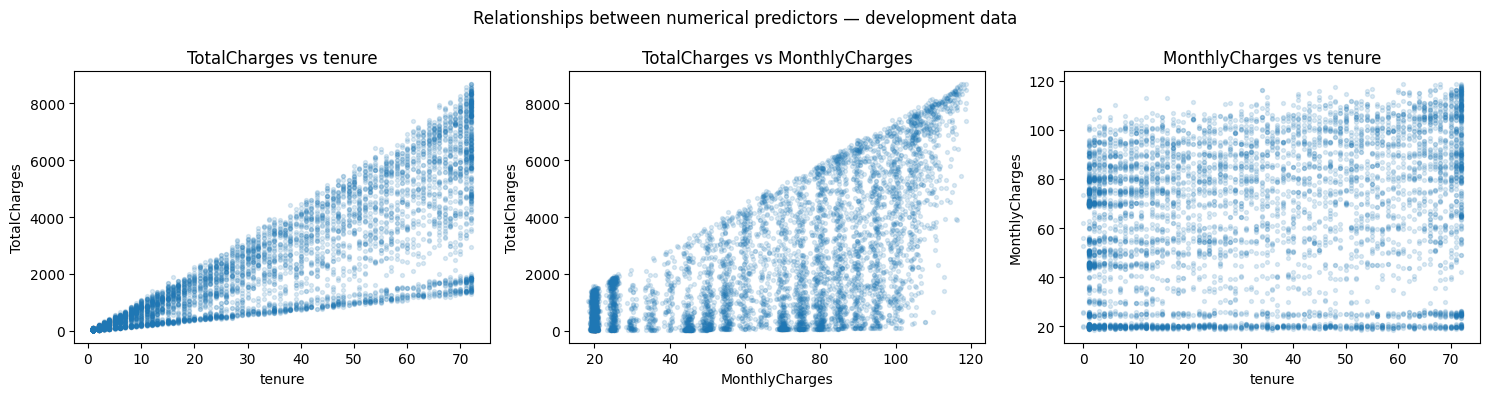

In [19]:
#scatterplots to inspect the actual shapes
pairs = [
    ("tenure", "TotalCharges"),
    ("MonthlyCharges", "TotalCharges"),
    ("tenure", "MonthlyCharges")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (x_column, y_column) in zip(axes, pairs):
    pair_data = eda[[x_column, y_column]].dropna()

    ax.scatter(
        pair_data[x_column],
        pair_data[y_column],
        s=8,
        alpha=0.15
    )

    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)
    ax.set_title(f"{y_column} vs {x_column}")

fig.suptitle("Relationships between numerical predictors — development data")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "development_numeric_relationships.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#Each point represents a development customer with both values available. The plots help us avoid relying on a correlation number alone.

### EDA-10 — Relationships between numerical predictors

Tenure and TotalCharges have a strong positive association (Pearson 0.829; Spearman 0.891). MonthlyCharges and TotalCharges are also positively associated (Pearson 0.654; Spearman 0.642). Tenure and MonthlyCharges have a weaker association (Pearson 0.257; Spearman 0.284).

Comparisons involving TotalCharges use 5,626 complete pairs; the tenure–MonthlyCharges comparison uses 5,634 records.

**Implication:** The numerical predictors contain overlapping information. This may affect coefficient interpretation in some models, but pairwise correlations alone do not justify feature removal. Retain the variables as candidates and consider model-specific treatment during development. These findings do not establish an exact formula for TotalCharges.

In [20]:
# Build the data dictionary.
# Merge the saved source review and document the final preprocessing.
# Observed values and missing counts describe development data before imputation.
descriptions = {
    "customerID": "Customer identifier.",
    "gender": "Recorded gender category.",
    "SeniorCitizen": "Recorded senior-citizen indicator (0/1).",
    "Partner": "Whether the customer is recorded as having a partner.",
    "Dependents": "Whether the customer is recorded as having dependents.",
    "tenure": "Recorded duration of the customer relationship, in months.",
    "PhoneService": "Whether the customer has phone service.",
    "MultipleLines": "Recorded multiple-phone-line service status.",
    "InternetService": "Recorded internet service type or absence of service.",
    "OnlineSecurity": "Recorded online security subscription status.",
    "OnlineBackup": "Recorded online backup subscription status.",
    "DeviceProtection": "Recorded device protection subscription status.",
    "TechSupport": "Recorded technical support subscription status.",
    "StreamingTV": "Recorded streaming TV subscription status.",
    "StreamingMovies": "Recorded streaming movies subscription status.",
    "Contract": "Recorded contract term.",
    "PaperlessBilling": "Whether paperless billing is recorded.",
    "PaymentMethod": "Recorded payment method.",
    "MonthlyCharges": "Recorded monthly charge amount.",
    "TotalCharges": "Recorded accumulated charge amount.",
    "Churn": "Recorded churn outcome; Yes is the positive class."
}

# Prevent an unnoticed missing description if the column list changes.
assert set(descriptions) == set(eda.columns)

data_dictionary = data_inventory.copy()
data_dictionary["Description"] = (
    data_dictionary["Column"].map(descriptions)
)

# Record the current EDA type separately from the original loaded type.
data_dictionary["EDA dtype"] = [
    str(eda[column].dtype)
    for column in data_dictionary["Column"]
]

def observed_values(column):
    """Describe development values without listing customer identifiers."""
    if column == "customerID":
        return "Unique identifier; individual values not listed"

    if column in numeric_features:
        values = eda[column].dropna()
        return f"Observed range: {values.min():g} to {values.max():g}"

    values = sorted(eda[column].dropna().unique(), key=str)
    return " | ".join(str(value) for value in values)

data_dictionary["Observed values — development only"] = [
    observed_values(column)
    for column in data_dictionary["Column"]
]

# Final documentation update:
# These notes describe preprocessing implemented later in Notebook 02.
# This cell does not change the observations or fit preprocessing.

def handling_note(column):
    """Describe the implemented treatment of each original column."""
    if column == "customerID":
        return (
            "Retained separately for integrity checks and joins; "
            "excluded from model predictors."
        )

    if column == "Churn":
        return (
            "Target only; encoded No = 0 and Yes = 1. "
            "Excluded from predictors."
        )

    if column == "TotalCharges":
        missing_count = int(eda[column].isna().sum())
        return (
            "Whitespace is stripped and valid amounts are parsed numerically. "
            "Documented blanks remain missing; unexpected non-numeric "
            f"content causes failure. {missing_count} development values "
            "are missing before imputation. Numerical missing values are "
            "replaced using medians learned from the training records "
            "available to each fit. StandardScaler is applied for logistic "
            "regression only; other candidate pipelines retain unscaled "
            "numerical values."
        )

    if column in numeric_features:
        return (
            "Numerical predictor. Median imputation is learned from the "
            "training records available to each fit. StandardScaler is "
            "applied for logistic regression only; other candidate "
            "pipelines retain unscaled numerical values."
        )

    note = (
        "One-hot encoded with drop=None, handle_unknown='ignore' and "
        "dense output. Recorded categories, including service-absence "
        "states where applicable, are retained. Missing or blank "
        "categorical inputs cause failure for review."
    )

    if column == "SeniorCitizen":
        note = "Treated as categorical despite integer storage. " + note

    return note

data_dictionary["Handling note"] = [
    handling_note(column)
    for column in data_dictionary["Column"]
]

# Do not infer currency or the senior-citizen age boundary from the CSV.
data_dictionary["Definition verification"] = (
    "Working description; original source documentation review pending."
)


#This is a usable working dictionary. Before the handover is final, add the original dataset documentation reference and verify definitions against it. Do not invent a currency, age boundary or predictor measurement date.
# Keep manually reviewed definitions in a separate file so reruns preserve them.
# Complete this file after reviewing the exact dataset documentation; do not
# replace the pending status with verified until that review actually happens.
REVIEW_FILE = PROJECT_DIR / "data" / "dictionary_source_review.csv"
review_columns = ["Reviewed description", "Definition source", "Source reviewed on",
                  "Unresolved details", "Review status"]
if not REVIEW_FILE.exists():
    review = pd.DataFrame({"Column": data_dictionary["Column"]})
    for column in review_columns:
        review[column] = ""
    review["Review status"] = "Pending source review"
    review.to_csv(REVIEW_FILE, index=False)
else:
    review = pd.read_csv(REVIEW_FILE, dtype=str, keep_default_na=False)

assert review["Column"].is_unique
assert set(review["Column"]) == set(eda.columns)
assert set(review_columns).issubset(review.columns)
review = review.set_index("Column")
for column in review_columns:
    data_dictionary[column] = data_dictionary["Column"].map(review[column])
has_reviewed_text = data_dictionary["Reviewed description"].str.strip().ne("")
data_dictionary.loc[has_reviewed_text, "Description"] = data_dictionary.loc[
    has_reviewed_text, "Reviewed description"
]
data_dictionary["Definition verification"] = data_dictionary["Review status"]
print("Definition review file:", REVIEW_FILE)

# Display the final dictionary after merging the saved source review.
print("Recorded source-review statuses:")
print(data_dictionary["Definition verification"].value_counts(dropna=False))
display(data_dictionary)

# Count dictionary entries and their recorded review statuses.
print("Total dictionary rows:", len(data_dictionary))
print(data_dictionary["Definition verification"].value_counts(dropna=False))

Definition review file: /content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn/data/dictionary_source_review.csv
Recorded source-review statuses:
Definition verification
Basic definition verified against supplied Kaggle metadata    21
Name: count, dtype: int64


,Column,Role,Analytical type,Loaded dtype,Distinct observed values,Missing values,Description,EDA dtype,Observed values — development only,Handling note,Definition verification,Reviewed description,Definition source,Source reviewed on,Unresolved details,Review status
0,customerID,Identifier — exclude from model inputs,Identifier,string,5634,0,Customer identifier.,string,Unique identifier; individual values not listed,Retained separately for integrity checks and j...,Basic definition verified against supplied Kag...,Customer identifier.,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
1,gender,Candidate predictor,Categorical,object,2,0,Customer’s recorded gender: Female or Male.,object,Female | Male,"One-hot encoded with drop=None, handle_unknown...",Basic definition verified against supplied Kag...,Customer’s recorded gender: Female or Male.,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
2,SeniorCitizen,Candidate predictor,Categorical,int64,2,0,"Whether the customer is a senior citizen, reco...",int64,0 | 1,Treated as categorical despite integer storage...,Basic definition verified against supplied Kag...,"Whether the customer is a senior citizen, reco...","BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,Exact age boundary is not specified.,Basic definition verified against supplied Kag...
3,Partner,Candidate predictor,Categorical,object,2,0,Whether the customer has a partner.,object,No | Yes,"One-hot encoded with drop=None, handle_unknown...",Basic definition verified against supplied Kag...,Whether the customer has a partner.,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
4,Dependents,Candidate predictor,Categorical,object,2,0,Whether the customer has dependents.,object,No | Yes,"One-hot encoded with drop=None, handle_unknown...",Basic definition verified against supplied Kag...,Whether the customer has dependents.,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
5,tenure,Candidate predictor,Numeric,int64,73,0,Number of months the customer has stayed with ...,int64,Observed range: 0 to 72,Numerical predictor. Median imputation is lear...,Basic definition verified against supplied Kag...,Number of months the customer has stayed with ...,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
6,PhoneService,Candidate predictor,Categorical,object,2,0,Whether the customer has phone service.,object,No | Yes,"One-hot encoded with drop=None, handle_unknown...",Basic definition verified against supplied Kag...,Whether the customer has phone service.,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
7,MultipleLines,Candidate predictor,Categorical,object,3,0,Whether the customer has multiple telephone li...,object,No | No phone service | Yes,"One-hot encoded with drop=None, handle_unknown...",Basic definition verified against supplied Kag...,Whether the customer has multiple telephone li...,"BlastChar, Telco Customer Churn, Kaggle — http...",23/09/2026,None identified in the basic definition reviewed.,Basic definition verified against supplied Kag...
8,InternetService,Candidate predictor,Categorical,object,3,0,"Recorded internet service category: DSL, Fiber...",object,DSL | Fiber optic | No,"One-hot encoded with drop=None, handle_unknown...",Basic definition verified against supplied Kag...,"Recorded internet service category: DSL, Fiber...","BlastChar, 

Total dictionary rows: 21
Definition verification
Basic definition verified against supplied Kaggle metadata    21
Name: count, dtype: int64


In [21]:
#Save your EDA tables
# Save generated evidence separately from raw data and fixed split files.
TABLE_DIR = PROJECT_DIR / "outputs" / "tables"
FIGURE_DIR = PROJECT_DIR / "outputs" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Tables whose index contains meaningful labels are saved with the index.
indexed_tables = {
    "development_target_distribution.csv": target_summary,
    "development_numeric_summary.csv": eda[numeric_features].describe().T,
    "development_contract_churn.csv": contract_summary,
    "development_pearson_correlations.csv": pearson_corr,
    "development_spearman_correlations.csv": spearman_corr,
    "development_correlation_pair_counts.csv": pair_counts,
}

for filename, table in indexed_tables.items():
    table.to_csv(TABLE_DIR / filename, index=True)

# These tables already store all labels in ordinary columns.
plain_tables = {
    "development_data_dictionary.csv": data_dictionary,
    "development_service_consistency.csv": service_consistency,
    "development_categorical_churn.csv": categorical_churn_summary,
    "development_payment_by_contract.csv": payment_by_contract,
}

for filename, table in plain_tables.items():
    table.to_csv(TABLE_DIR / filename, index=False)

# Flatten the two-level summary headings for a readable exported CSV.
numeric_export = numeric_by_churn.copy()
numeric_export.columns = [
    f"{feature}_{statistic}"
    for feature, statistic in numeric_export.columns
]
numeric_export.to_csv(
    TABLE_DIR / "development_numeric_by_churn.csv",
    index=True
)

print("Saved EDA tables to:", TABLE_DIR)

#Rerunning this cell updates these generated tables. It does not overwrite your original CSV or split files.

Saved EDA tables to: /content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn/outputs/tables


In [22]:
# Check expected outputs and save a dated evidence record after a full run.
expected_tables = list(indexed_tables) + list(plain_tables) + [
    "development_numeric_by_churn.csv"
]
expected_figures = [
    "development_numeric_distributions.png",
    "development_numeric_by_churn.png",
    "development_numeric_relationships.png"
]
for folder, names in [(TABLE_DIR, expected_tables), (FIGURE_DIR, expected_figures)]:
    for name in names:
        path = folder / name
        assert path.is_file() and path.stat().st_size > 0, f"Missing output: {path}"

assert eda.shape == (5634, 21)
assert eda["customerID"].is_unique
assert eda["Churn"].value_counts().to_dict() == {"No": 4139, "Yes": 1495}
assert eda["TotalCharges"].isna().sum() == 8

run_record = {
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_sha256": raw_hash,
    "development_shape": list(eda.shape),
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "table_count": len(expected_tables),
    "figure_count": len(expected_figures),
    "dictionary_source_review_pending": bool(
        data_dictionary["Definition verification"].str.contains("pending", case=False).any()
    )
}
(TABLE_DIR / "eda_run_record.json").write_text(
    json.dumps(run_record, indent=2), encoding="utf-8"
)
print("Output checks passed. Open the CSVs and images for a visual check.")
print("This record confirms cell completion; record a fresh-session rerun separately.")


Output checks passed. Open the CSVs and images for a visual check.
This record confirms cell completion; record a fresh-session rerun separately.


### Handover to IT24103676 — Preprocessing

**Inputs available**

The fixed development subset contains 5,634 customer records. Use the saved development.csv and existing split membership. The reserved test set remains for final evaluation.

The notebook contains the data inventory, EDA interpretations, service-consistency checks, descriptive comparisons and numerical correlation analysis. Generated tables and figures are saved under outputs.

**Preprocessing matters requiring decisions**

- Exclude customerID and Churn from predictors.
- Parse TotalCharges numerically and justify treatment of its eight missing development values. All eight have tenure zero; this does not independently prove that zero is the correct replacement.
- Treat SeniorCitizen as categorical and preserve meaningful service-state categories.
- Choose categorical encoding and model-appropriate scaling.
- Do not remove large values solely because they appear as boxplot outliers.
- Consider the overlapping information in tenure and TotalCharges when choosing and interpreting models.
- Assess class weighting only with a justified development comparison; do not balance the data automatically.
- Fit all learned transformations within cross-validation training folds.

**Completion checks**

Verified dictionary definitions against the original dataset documentation, confirmed saved outputs, and reran the notebook from top to bottom using the existing split. Recorded any unresolved issues before handover.

Reproducibility check: On 12/10/2026, the notebook was run from a fresh Colab session, from top to bottom, without errors. The existing development/test split was reused.